# Same batters or different batters?

**The question, given the season contrasts.** The league powerplay six rate rose about 40% between 2023 and 2024 with no measurable wicket cost. The project has treated that as a change in how teams bat, but a league rate is a ball-weighted average of the batters who faced those balls, and it can rise for two quite different reasons: the same batters hit more sixes, or the powerplay balls were faced by different batters. The first is tactical evolution; the second is recruitment and selection. This notebook separates them.

**What this notebook does.**
1. Splits the season change in the league powerplay six rate exactly into a *within* part (continuing batters changed their rate, at average ball shares) and a *composition* part (the ball shares moved between batters, at average rates), with composition further split into entrants (batters in 2024 only), exits (2023 only), and reweighting among continuing batters. The identity holds on every resample of the match cluster bootstrap.
2. Shows the per-batter picture: each continuing batter's rate in both seasons with an interval on the change, and the size of their contribution.
3. Recomputes the league contrast on continuing batters only, beside the all-batter contrast on the same draws, as the plain-language version of the question.
4. Runs the same decomposition for the boundary rate and run rate in the powerplay, and for the six rate in the middle and death overs.

**How to read this notebook.** *Within* means the same batters changed; *composition* means different batters faced the balls. A batter is *continuing* if he faced at least one powerplay ball in both seasons (the decomposition needs no floor); a batter's own rate is displayed and tested only at 30 or more balls in both seasons. *Entrants* and *exits* are batters present in one season only, whatever the reason (new signing, promotion up the order, injury, dropped). All intervals are 95% percentile intervals on shared match draws unless stated.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/batter_continuity/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from batter_continuity import six_rate_decomposition as bc

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "batter_continuity"
SEED = settings.seed("global")
N_ITER = settings.n_resamples
MIN_BALLS = int(settings.section("batter_continuity")["min_balls_per_season"])
PRODUCER = "batter_continuity.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}  min balls per season={MIN_BALLS}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  min balls per season=30


## Data

The cleaned two-season frame; 232 distinct batters faced a ball across the two seasons.

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (mechanics only, no findings)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}  batters={df['p_bat'].nunique()}")
EXTRA = {"n_resamples": N_ITER, "min_balls_per_season": MIN_BALLS, "fixture": USING_FIXTURE}

rows=34,967  matches=145  batters=232


## Powerplay six rate: same batters against different batters

Components with intervals and P(positive); `identity_max_abs_error` should be at floating-point precision. Then the per-batter table (continuing batters at the floor, sorted by the size of their contribution) and the scatter of continuing batters, earlier rate against later rate, sized by balls faced.

In [3]:
six = bc.run_decomposition(df, settings, SEED, "six_rate", "powerplay", n_iter=N_ITER)
print("batters:", six["n_batters"], "| identity max abs error:", six["components"].attrs["identity_max_abs_error"])
results_io.write_table(six["components"], settings, ANALYSIS, "powerplay_six_rate_components", SEED, PRODUCER, EXTRA)
results_io.write_table(six["batters"], settings, ANALYSIS, "powerplay_six_rate_by_batter", SEED, PRODUCER, EXTRA)
six["components"].round(5)

batters: {'continuing': 55, 'entrants': 28, 'exits': 32, 'continuing_meeting_floor': 30} | identity max abs error: 1.5612511283791264e-17


,quantity,estimate,ci_low,ci_high,p_positive,interval_method
0,league_earlier,0.04623,0.04014,0.05276,1.0000,percentile
1,league_later,0.06425,0.05536,0.07379,1.0000,percentile
2,league_change,0.01802,0.00699,0.02924,0.9995,percentile
3,within,0.00788,-0.00035,0.01612,0.9692,percentile
4,composition,0.01014,0.00273,0.01800,0.9971,percentile
5,composition_continuing_reweight,0.00152,-0.00411,0.00699,0.6956,percentile
6,composition_entrants,0.01558,0.01107,0.02376,1.0000,percentile
7,composition_exits,-0.00695,-0.01219,-0.00467,0.0000,percentile
8,share_later_faced_by_entrants,0.22216,0.19673,0.29071,1.0000,percentile
9,share_earlier_faced_by_exits,0.19677,0.17423,0.27107,1.0000,percentile


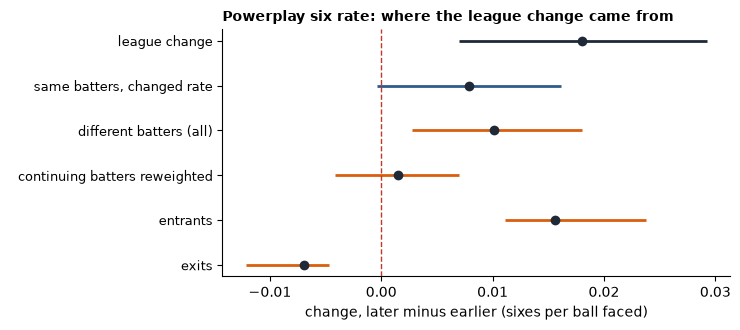

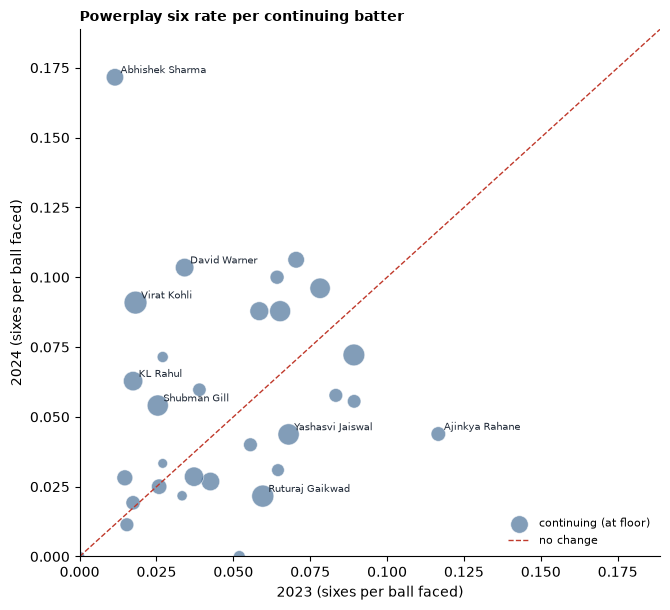

,p_bat,bat,status,balls_2023,balls_2024,rate_2023,rate_2024,rate_change,change_low,change_high,within_contribution,meets_floor_both_seasons
0,1070183,Abhishek Sharma,continuing,87,169,0.0115,0.1716,0.1601,0.0987,0.2273,0.0039,True
1,253802,Virat Kohli,continuing,220,231,0.0182,0.0909,0.0727,0.0267,0.1253,0.0031,True
2,219889,David Warner,continuing,205,87,0.0341,0.1034,0.0693,0.0093,0.1198,0.0019,True
4,1060380,Ruturaj Gaikwad,continuing,235,185,0.0596,0.0216,-0.0380,-0.0791,0.0015,-0.0015,True
5,422108,KL Rahul,continuing,115,207,0.0174,0.0628,0.0454,0.0057,0.0791,0.0014,True
7,277916,Ajinkya Rahane,continuing,60,114,0.1167,0.0439,-0.0728,-0.1207,0.0061,-0.0012,True
8,1070173,Shubman Gill,continuing,236,148,0.0254,0.0541,0.0286,-0.0115,0.0741,0.0010,True
9,1151278,Yashasvi Jaiswal,continuing,206,183,0.0680,0.0437,-0.0242,-0.0613,0.0150,-0.0009,True
10,1161024,Prabhsimran Singh,continuing,154,148,0.0584,0.0878,0.0294,-0.0363,0.0913,0.0008,True
11,720471,Ishan Kishan,continuing,230,148,0.0652,0.0878,0.0226,-0.0513,0.0927,0.0008,True


In [4]:
fig = bc.plot_components(six["components"], six["unit"], "Powerplay six rate: where the league change came from")
results_io.write_figure(fig, settings, ANALYSIS, "powerplay_six_rate_components", SEED, PRODUCER)
plt.show()
fig = bc.plot_batter_scatter(six["batters"], YEARS[0], YEARS[1], six["unit"], "Powerplay six rate per continuing batter")
results_io.write_figure(fig, settings, ANALYSIS, "powerplay_six_rate_batter_scatter", SEED, PRODUCER)
plt.show()
six["batters"][six["batters"]["meets_floor_both_seasons"]].head(20).round(4)

The league powerplay six rate rose from 4.6% to 6.4% of balls, +1.8 points (interval +0.7 to +2.9). Of that, the same batters account for +0.8 points (interval −0.04 to +1.6, P 0.97) and different batters for +1.0 points (interval +0.3 to +1.8, P 0.997). The composition part is almost all entrants against exits: batters new to the 2024 powerplay faced 22% of its balls and hit sixes at 7.0% of them, against 3.5% for the batters they replaced, who had faced 20% of the 2023 balls; reweighting among continuing batters contributed nothing (+0.15, P 0.70). So the honest split is roughly half and half: the same batters did hit more sixes, and the league also put higher-hitting batters at the top of the order.

The within part is concentrated. Of 30 continuing batters at the floor, three carry more than the whole within term: Abhishek Sharma (1.2% to 17.2% of balls, interval on the change +10 to +23 points), Virat Kohli (1.8% to 9.1%, +3 to +13) and David Warner (3.4% to 10.3%, +1 to +12), with KL Rahul also clearing (+0.6 to +7.9). Ruturaj Gaikwad and Ajinkya Rahane moved the other way, just short of clearing. Most continuing batters did not change measurably. "The same batters hit more sixes" is true of a handful of openers, not of the field.

## Continuing batters only, as a season contrast

The league powerplay six rate recomputed on the 30 batters at or above the floor in both seasons, beside the all-batter contrast, on the same draws (bootstrap-t intervals; the ratio on the log scale).

In [5]:
continuing = bc.continuing_batter_contrast(df, settings, SEED, "six_rate", "powerplay", six["counts"], MIN_BALLS)
results_io.write_table(continuing, settings, ANALYSIS, "powerplay_six_rate_continuing_contrast", SEED, PRODUCER, EXTRA)
continuing[["theme", "estimate", "ci_low", "ci_high", "interval_method", "resampling_stable", "n_continuing_batters"]].round(4)

,theme,estimate,ci_low,ci_high,interval_method,resampling_stable,n_continuing_batters
0,powerplay_six_rate_diff_all_batters,0.0180,0.0069,0.0297,bootstrap_t,True,30
1,powerplay_six_rate_ratio_all_batters,1.3898,1.1353,1.7002,bootstrap_t,True,30
2,powerplay_six_rate_diff_continuing_batters_only,0.0143,0.0020,0.0268,bootstrap_t,True,30
3,powerplay_six_rate_ratio_continuing_batters_only,1.2939,1.0326,1.6064,bootstrap_t,True,30


On continuing batters alone the powerplay six rate rose from 4.9% to 6.3%: +1.4 points (interval +0.2 to +2.7), a ratio of 1.29 (interval 1.03 to 1.61). It clears, against 1.39 (1.14 to 1.70) for all batters. The evolution reading survives on the batters who were there in both seasons, at about three quarters of the all-batter size, which matches the decomposition's split.

## Other rates in the powerplay, and the six rate in the other phases

The same decomposition on the same draws: boundary rate and run rate in the powerplay; six rate in the middle and the death.

In [6]:
rows = []
for rate, phase in (("boundary_rate", "powerplay"), ("run_rate", "powerplay"),
                    ("six_rate", "middle"), ("six_rate", "death")):
    out = bc.run_decomposition(df, settings, SEED, rate, phase, n_iter=N_ITER, counts=six["counts"])
    comp = out["components"].copy()
    comp.insert(0, "rate", rate)
    comp.insert(1, "phase", phase)
    comp["n_continuing"] = out["n_batters"]["continuing"]
    rows.append(comp)
other = pd.concat(rows, ignore_index=True)
results_io.write_table(other, settings, ANALYSIS, "other_rates_components", SEED, PRODUCER, EXTRA)
other[other["quantity"].isin(["league_change", "within", "composition", "composition_entrants", "composition_exits"])].round(4)

,rate,phase,quantity,estimate,ci_low,ci_high,p_positive,interval_method,n_continuing
2,boundary_rate,powerplay,league_change,0.0231,0.0033,0.0438,0.9893,percentile,55
3,boundary_rate,powerplay,within,0.0101,-0.0071,0.0246,0.8556,percentile,55
4,boundary_rate,powerplay,composition,0.0130,-0.0004,0.0302,0.9704,percentile,55
6,boundary_rate,powerplay,composition_entrants,0.0588,0.0472,0.0825,1.0000,percentile,55
7,boundary_rate,powerplay,composition_exits,-0.0393,-0.0578,-0.0322,0.0000,percentile,55
16,run_rate,powerplay,league_change,0.7279,0.1685,1.3003,0.9957,percentile,55
17,run_rate,powerplay,within,0.2949,-0.1832,0.7234,0.8742,percentile,55
18,run_rate,powerplay,composition,0.4330,0.0457,0.9057,0.9854,percentile,55
20,run_rate,powerplay,composition_entrants,2.0704,1.7206,2.8556,1.0000,percentile,55
21,run_rate,powerplay,composition_exits,-1.4694,-2.1134,-1.2324,0.0000,percentile,55


Outside the powerplay the story is turnover, not evolution. The middle-overs six rate rose 0.8 points with the within part at −0.2 (P 0.29) and composition at +1.0 (interval +0.4 to +1.8); the death rose 1.2 points with within at +0.1 and composition at +1.1 (P 0.96). In both phases the batters who arrived hit sixes at roughly twice the rate of the batters who left. In the powerplay the other rates split the way the six rate does: boundary rate +2.3 points with within +1.0 (P 0.86) and composition +1.3 (P 0.97); run rate +0.73 runs per over with within +0.29 (P 0.87) and composition +0.43 (interval +0.05 to +0.91, clears).

## Were the entrants bought or promoted?

The auction tables give each player's status per season, so the composition half of the decomposition can be split by how each entrant came to face 2024 powerplay balls: bought at the 2024 auction, traded in, already in a squad and newly given powerplay balls (promoted), or not on any auction list (a mid-season replacement signing). Exits are split the same way by how they left. Names are reconciled to dataset ids by an exact key, then surname plus first initial, with a short fix list; a surname-only fallback was tried and dropped because it paired players who share a surname. The match report and the players in the data with no auction row come first.

In [7]:
from common import auction as auc
from batter_continuity import auction_status as auction_status

auction_table = auc.load_auction(settings.data_path("auction_workbook"))
players = auc.dataset_players(df)
matched, unmatched = auc.match_auction_to_dataset(auction_table, players)
results_io.write_table(matched, settings, ANALYSIS, "auction_matched", SEED, PRODUCER, EXTRA)
display(auc.match_report(matched))
in_data_unmatched = players[~players["player_id"].isin(matched["player_id"].dropna())]
print(f"players in the data with no auction row in either season: {len(in_data_unmatched)}")
display(in_data_unmatched.head(30))
matched[matched["match_method"] == "unique_surname"][["season", "player_name", "status", "team", "player_id"]].merge(players, on="player_id")

,season,status,rows,matched,match_rate
0,2023,Retained,153,139,0.908497
1,2023,Sold,80,62,0.775
2,2023,Traded,5,5,1.0
3,2023,Unsold,62,18,0.290323
4,2024,Retained,166,155,0.933735
5,2024,Sold,72,53,0.736111
6,2024,Traded,7,7,1.0
7,2024,Unsold,62,19,0.306452


players in the data with no auction row in either season: 13


,player_id,name
105,605575,Matthew Short
157,290716,Kedar Jadhav
211,917231,BR Sharath
214,1168049,Jake Fraser-McGurk
216,267724,Keshav Maharaj
221,379887,Lizaad Williams
225,473191,Richard Gleeson
226,352048,Gulbadin Naib
231,1153149,Vijayakanth Viyaskanth
243,379776,Sisanda Magala


,season,player_name,status,team,player_id,name


Match rates are 91% to 93% for retained players and 74% to 78% for sold ones; the unmatched remainder are squad members who never faced or bowled a ball. Thirteen players in the data have no auction row in either season, and all thirteen are mid-season replacement signings (Fraser-McGurk, Keshav Maharaj, Shamar Joseph and the rest), which is how they should read. No initial-based matches remain to review.

In [8]:
batters_status = auction_status.entrant_status(six["batters"], matched, YEARS[0], YEARS[1])
routes = auction_status.composition_by_route(batters_status, YEARS[0], YEARS[1])
results_io.write_table(batters_status, settings, ANALYSIS, "powerplay_six_rate_by_batter_with_auction_status", SEED, PRODUCER, EXTRA)
results_io.write_table(routes, settings, ANALYSIS, "composition_by_auction_route", SEED, PRODUCER, EXTRA)
display(routes.round(4))
batters_status[batters_status["status"] == "entrant"].sort_values(f"balls_{YEARS[1]}", ascending=False)[
    ["bat", "entry_route", "team_later", "price_later_cr", f"balls_{YEARS[1]}", f"rate_{YEARS[1]}"]].head(15).round(3)

,group,route,batters,balls,share_of_season_balls,six_rate,composition_contribution,median_price_cr
0,entrant,bought,15,636,0.1238,0.0660,0.0082,0.75
1,entrant,not_in_auction_table,2,126,0.0245,0.1667,0.0041,NaN
2,entrant,promoted_from_squad,11,379,0.0738,0.0449,0.0033,3.20
3,exit,unsold,4,54,0.0101,0.0185,-0.0002,NaN
4,exit,moved_team,3,123,0.0231,0.0163,-0.0004,NaN
5,exit,not_in_auction_table,11,214,0.0402,0.0280,-0.0011,NaN
6,exit,retained_not_used,14,656,0.1233,0.0427,-0.0053,NaN


,bat,entry_route,team_later,price_later_cr,balls_2024,rate_2024
112,Travis Head,bought,Sunrisers Hyderabad,6.80,193,0.114
88,Jonny Bairstow,promoted_from_squad,Punjab Kings,6.75,117,0.034
50,Rachin Ravindra,bought,Chennai Super Kings,1.80,110,0.064
66,Jake Fraser-McGurk,not_in_auction_table,NaN,NaN,106,0.198
77,Daryl Mitchell,bought,Chennai Super Kings,14.00,73,0.027
108,Shai Hope,bought,Delhi Capitals,0.75,60,0.067
94,Tom Kohler-Cadmore,bought,Rajasthan Royals,0.40,51,0.020
48,Angkrish Raghuvanshi,bought,Kolkata Knight Riders,0.20,49,0.082
57,Will Jacks,promoted_from_squad,Royal Challengers Bengaluru,3.20,49,0.102
62,Riyan Parag,promoted_from_squad,Rajasthan Royals,3.80,40,0.050


Of the +1.56 points of powerplay six rate that entrants contributed, +0.82 came from fifteen batters bought at the 2024 auction (636 balls, 12% of the powerplay, six rate 6.6%, median price 0.75 crore, so mostly cheap buys), +0.41 from the two replacement signings not on any list (Jake Fraser-McGurk at 19.8% on 106 balls is nearly all of it), and +0.33 from eleven batters already in a squad and newly given powerplay balls (six rate 4.5%). Recruitment, then, is about three quarters of the entrant effect and promotion a quarter. Travis Head (Sunrisers, 6.8 crore, 11.4%) is the largest bought contribution; Daryl Mitchell at 14 crore hit sixes at 2.7%. The exits were mostly batters teams kept but moved out of the powerplay (fourteen, 656 balls, 4.3%), not batters released or unsold.

Half of the powerplay rise was three continuing openers hitting more sixes, and most of the other half was batters teams bought or signed to do exactly that.

The 2024 rise in six hitting was part evolution and part recruitment, and the mix differs by phase. In the powerplay about half of the league change is the same batters hitting more sixes, driven by three openers, and half is higher-hitting batters facing the balls; the auction tables place three quarters of that second half with batters teams bought or signed (Travis Head, Jake Fraser-McGurk, Rachin Ravindra among them) and a quarter with batters promoted from within squads. In the middle and death overs it is almost entirely different batters. The tactical-evolution claim is strongest where the project already placed it, in the powerplay, and reads as "the same openers hit more sixes, and teams bought hitters to join them"; the broader rise in aerial hitting across the innings is better described as a change in who bats than in how they bat.